# Analisi del weekend

Notebook per esplorare le partite del weekend e costruire schedine. Usa i file creati da `weekend.py`:
lancia prima `python3 weekend.py lista` (venerdì), poi *Run All* qui.

Ogni sezione ha in cima i parametri da cambiare (in MAIUSCOLO).

- **Prob**: probabilità equa, ricavata dalle quote di mercato senza margine
- **Equa**: quota senza margine (= 1 / Prob)
- **Quota**: quota di mercato per 1X2 e U/O 2.5; stimata per le altre giocate (`Stimata = True`)
- **Valore**: Quota × Prob − 1, cioè quanto rende in media ogni euro (negativo = margine del book)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from weekend import (MENU, find_match, fit_goals, load_matches, market_menu, score_grid,
                     selection_mask, weekend_dir, weekend_menu)
from bet_model import LEAGUES, fair_probs

pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)
BLU = "#2563eb"

WEEKEND = None  # es. "2026-10-16"; None = l'ultimo salvato
wdir = weekend_dir(Path("schedine"), WEEKEND)
matches = load_matches(wdir)
menu = weekend_menu(matches)
print(f"Weekend {wdir.name}: {len(matches)} partite, {len(menu)} giocate valutate")
matches.assign(Gol_casa=matches["lam"], Gol_trasferta=matches["mu"])[
    ["Div", "Date", "Time", "Partita", "Gol_casa", "Gol_trasferta"]]

Weekend 2026-10-17: 54 partite, 2322 giocate valutate


,Div,Date,Time,Partita,Gol_casa,Gol_trasferta
0,E0,2026-10-17,12:30,Everton - Chelsea,1.34,1.65
1,SP1,2026-10-17,13:00,Espanyol - Atlético Madrid,1.00,1.83
2,I1,2026-10-17,14:00,Venezia - Napoli,1.05,1.87
3,D1,2026-10-17,14:30,Elversberg - Augsburg,1.71,1.66
4,D1,2026-10-17,14:30,Union Berlin - Borussia Dortmund,1.12,2.14
5,D1,2026-10-17,14:30,FC Schalke 04 - FSV Mainz 05,1.41,1.63
6,D1,2026-10-17,14:30,Hamburger SV - VfB Stuttgart,1.40,2.11
7,D1,2026-10-17,14:30,Werder Bremen - SC Paderborn,1.97,1.26
8,E0,2026-10-17,15:00,Brentford - Liverpool,1.62,1.50
9,E0,2026-10-17,15:00,Fulham - Hull City,1.85,1.02


## 1. Una partita nel dettaglio

La mappa mostra la probabilità di ogni risultato esatto; sotto, tutte le giocate della partita.

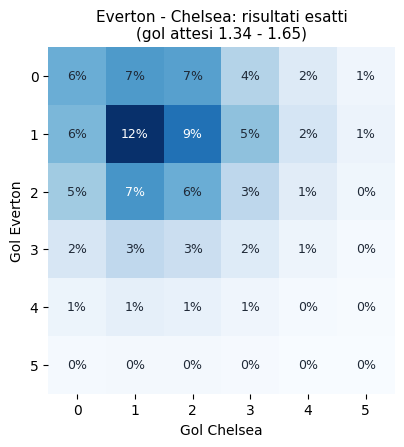

,Giocata,Prob,Equa,Quota,Stimata,Valore
0,O1.5,0.81,1.23,1.18,True,-0.05
1,12,0.74,1.36,1.29,True,-0.05
2,X2,0.70,1.43,1.36,True,-0.05
3,U3.5,0.65,1.54,1.47,True,-0.05
4,MG2-4,0.63,1.59,1.52,True,-0.05
5,GG,0.61,1.65,1.57,True,-0.05
6,MG1-3,0.59,1.70,1.62,True,-0.05
7,O2.5,0.57,1.74,1.65,False,-0.05
8,X2+O1.5,0.57,1.77,1.68,True,-0.05
9,1X,0.56,1.78,1.69,True,-0.05


In [2]:
PARTITA = None  # parte del nome di una squadra, es. "roma - genoa"; None = la prima partita

m = find_match(matches, PARTITA) if PARTITA else matches.iloc[0]
P = score_grid(m["lam"], m["mu"])[:6, :6]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(P, cmap="Blues")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{P[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if P[i, j] > P.max() * 0.6 else "#1f2937")
ax.set_xlabel(f"Gol {m['AwayTeam']}")
ax.set_ylabel(f"Gol {m['HomeTeam']}")
ax.set_title(f"{m['Partita']}: risultati esatti\n(gol attesi {m['lam']:.2f} - {m['mu']:.2f})", fontsize=11)
for s in ax.spines.values():
    s.set_visible(False)
plt.show()

market_menu(m).sort_values("Prob", ascending=False).reset_index(drop=True)

## 2. Cerca giocate in tutto il weekend

Filtra per probabilità, quota e tipo di giocata. `GIOCATE = None` le considera tutte
(lista completa in `MENU`).

In [3]:
PROB_MIN, PROB_MAX = 0.55, 0.80
QUOTA_MIN, QUOTA_MAX = 1.20, 2.00
GIOCATE = None          # es. ["GG", "1X+U3.5", "O2.5"]
LEGHE = None            # es. ["Serie A", "Premier League"]

f = menu[menu["Prob"].between(PROB_MIN, PROB_MAX) & menu["Quota"].between(QUOTA_MIN, QUOTA_MAX)]
if GIOCATE:
    f = f[f["Giocata"].isin(GIOCATE)]
if LEGHE:
    f = f[f["Lega"].isin(LEGHE)]
print(f"{len(f)} giocate trovate (MENU: {', '.join(MENU)})")
f.sort_values("Valore", ascending=False)[
    ["Ora", "Lega", "Partita", "Giocata", "Prob", "Equa", "Quota", "Stimata", "Valore"]].head(40)

422 giocate trovate (MENU: 1, X, 2, 1X, X2, 12, O1.5, U1.5, O2.5, U2.5, O3.5, U3.5, GG, NG, MG1-3, MG2-3, MG2-4, GG+O2.5, NG+U2.5, 1+O1.5, 1+U3.5, 1+O2.5, 1+U2.5, 1+GG, 1+NG, 2+O1.5, 2+U3.5, 2+O2.5, 2+U2.5, 2+GG, 2+NG, 1X+O1.5, 1X+U3.5, 1X+O2.5, 1X+U2.5, 1X+GG, 1X+NG, X2+O1.5, X2+U3.5, X2+O2.5, X2+U2.5, X2+GG, X2+NG)


,Ora,Lega,Partita,Giocata,Prob,Equa,Quota,Stimata,Valore
2287,mar 20/10 21:00,Champions League,Porto - PSV Eindhoven,O2.5,0.61,1.64,1.56,False,-0.05
446,sab 17/10 16:00,Premier League,Manchester City - Ipswich Town,MG2-4,0.59,1.71,1.63,True,-0.05
463,sab 17/10 16:00,Premier League,Manchester City - Ipswich Town,1X+O2.5,0.65,1.55,1.48,True,-0.05
449,sab 17/10 16:00,Premier League,Manchester City - Ipswich Town,1+O1.5,0.70,1.42,1.36,True,-0.05
451,sab 17/10 16:00,Premier League,Manchester City - Ipswich Town,1+O2.5,0.60,1.67,1.59,True,-0.05
14,sab 17/10 13:30,Premier League,Everton - Chelsea,MG1-3,0.59,1.70,1.62,True,-0.05
4,sab 17/10 13:30,Premier League,Everton - Chelsea,X2,0.70,1.43,1.36,True,-0.05
11,sab 17/10 13:30,Premier League,Everton - Chelsea,U3.5,0.65,1.54,1.47,True,-0.05
3,sab 17/10 13:30,Premier League,Everton - Chelsea,1X,0.56,1.78,1.69,True,-0.05
16,sab 17/10 13:30,Premier League,Everton - Chelsea,MG2-4,0.63,1.59,1.52,True,-0.05


## 3. Costruisci la tua schedina

Una riga per partita: `(squadra, giocata, quota del tuo book)`. Se non conosci la quota metti `None`
e viene usata quella stimata. Il nome deve individuare una sola partita (es. `"roma - genoa"`).
Se `SCHEDINA` è vuota viene usata la doppia proposta da `weekend.py proponi`. Sotto: vincita, probabilità e cosa succede giocandola ogni weekend per un anno
(simulazione, con la stessa probabilità ogni settimana).

Quota totale 3.06 · vincita 15.29 euro · probabilità 29.5% (1 volta su 3.4)
Valore atteso per giocata: -0.49 euro


,Partita,Giocata,Prob,Equa,Quota,Fonte,Valore
0,Espanyol - Atlético Madrid,X2+U3.5,0.54,1.84,1.75,stimata,-0.05
1,Bournemouth - Sunderland,X2,0.54,1.84,1.75,stimata,-0.05


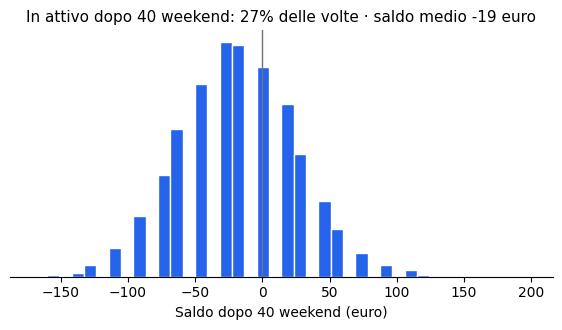

In [4]:
SCHEDINA = [
    # ("roma - genoa", "O2.5", None),
    # ("man city", "GG", 1.80),
]
if not SCHEDINA and (wdir / "proposte.csv").exists():
    pr = pd.read_csv(wdir / "proposte.csv")
    SCHEDINA = [(r.Partita, r.Giocata, None) for r in pr[pr["Schedina"] == "Doppia"].itertuples()]
PUNTATA = 5.0
SETTIMANE = 40

rows = []
for squadra, giocata, quota_book in SCHEDINA:
    mm = find_match(matches, squadra)
    r = market_menu(mm, [giocata.upper()]).iloc[0]
    q = quota_book or r["Quota"]
    rows.append({"Partita": mm["Partita"], "Giocata": r["Giocata"], "Prob": r["Prob"], "Equa": r["Equa"],
                 "Quota": q, "Fonte": "book" if quota_book else "stimata", "Valore": q * r["Prob"] - 1})
t = pd.DataFrame(rows)
q, p = t["Quota"].prod(), t["Prob"].prod()
print(f"Quota totale {q:.2f} · vincita {PUNTATA * q:.2f} euro · probabilità {p:.1%} (1 volta su {1 / p:.1f})")
print(f"Valore atteso per giocata: {PUNTATA * (q * p - 1):+.2f} euro")
display(t)

rng = np.random.default_rng(0)
vinte = rng.binomial(SETTIMANE, p, size=20_000)
saldo = vinte * PUNTATA * q - SETTIMANE * PUNTATA
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(saldo, bins=40, color=BLU, edgecolor="white", linewidth=1)
ax.axvline(0, color="#6b7280", linewidth=1)
ax.set_xlabel(f"Saldo dopo {SETTIMANE} weekend (euro)")
ax.set_yticks([])
ax.set_title(f"In attivo dopo {SETTIMANE} weekend: {np.mean(saldo > 0):.0%} delle volte · "
             f"saldo medio {saldo.mean():+.0f} euro", fontsize=11)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
plt.show()

## 4. Proposte e quote inserite

Le schedine generate da `python3 weekend.py proponi` e, se le hai inserite con `valuta`, le quote del tuo book
con il loro valore.

In [5]:
prop = wdir / "proposte.csv"
if prop.exists():
    pr = pd.read_csv(prop)
    tot = pr.groupby("Schedina", sort=False).agg(Partite=("Partita", "size"), Quota=("Quota", "prod"),
                                                 Prob=("Prob", "prod"), Puntata=("Puntata", "first"))
    tot["Vincita"] = tot["Quota"] * tot["Puntata"]
    display(tot)
    display(pr)
else:
    print("Nessuna proposta: lancia 'python3 weekend.py proponi'.")

book = wdir / "book.csv"
if book.exists():
    b = pd.read_csv(book).sort_values("Valore")
    display(b)
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(b) + 1))
    ax.barh(b["Partita"] + "  " + b["Giocata"], b["Valore"] * 100, color=BLU, height=0.6)
    ax.axvline(0, color="#6b7280", linewidth=1)
    ax.set_xlabel("Valore (%): sopra 0 il book paga più dell'equa")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.show()
else:
    print("Nessuna quota del book inserita (python3 weekend.py valuta).")

,Partite,Quota,Prob,Puntata,Vincita
Schedina,,,,,
Singola,1,1.69,0.57,5.00,8.43
Doppia,2,3.06,0.30,5.00,15.29
Tripla,3,5.62,0.15,5.00,28.08
Colpo,4,13.39,0.06,5.00,66.94


,Schedina,Ora,Lega,Partita,Giocata,Prob,Equa,Quota,Stimata,Puntata
0,Singola,sab 17/10 16:00,Premier League,Brentford - Liverpool,MG1-3,0.57,1.77,1.69,True,5.00
1,Doppia,sab 17/10 14:00,LaLiga,Espanyol - Atlético Madrid,X2+U3.5,0.54,1.84,1.75,True,5.00
2,Doppia,dom 18/10 15:00,Premier League,Bournemouth - Sunderland,X2,0.54,1.84,1.75,True,5.00
3,Tripla,sab 17/10 16:00,Premier League,Manchester City - Ipswich Town,GG,0.54,1.87,1.78,True,5.00
4,Tripla,sab 17/10 16:00,Premier League,Fulham - Hull City,1X+U3.5,0.53,1.87,1.78,True,5.00
5,Tripla,sab 17/10 21:00,LaLiga,Valencia - Athletic Bilbao,X2+U3.5,0.54,1.87,1.77,True,5.00
6,Colpo,dom 18/10 17:30,Premier League,Nottingham Forest - Arsenal,O2.5,0.50,2.01,1.91,False,5.00
7,Colpo,sab 17/10 16:15,LaLiga,Villarreal - Elche CF,GG+O2.5,0.50,2.02,1.91,True,5.00
8,Colpo,sab 17/10 15:30,Bundesliga,Hamburger SV - VfB Stuttgart,MG1-3,0.50,2.02,1.91,True,5.00
9,Colpo,dom 18/10 15:30,Bundesliga,Bayer Leverkusen - SC Freiburg,1+O1.5,0.49,2.03,1.92,True,5.00


Nessuna quota del book inserita (python3 weekend.py valuta).


## 5. Il modello dei gol funziona? Verifica sullo storico

Per un campione di partite passate ricalcola le probabilità solo dalle quote 1X2 e U/O 2.5 di apertura,
poi confronta con quello che è successo. Se i punti stanno sulla diagonale, le probabilità sono giuste.
Richiede i dati scaricati con `python3 bet_model.py --download`; circa 30 secondi.

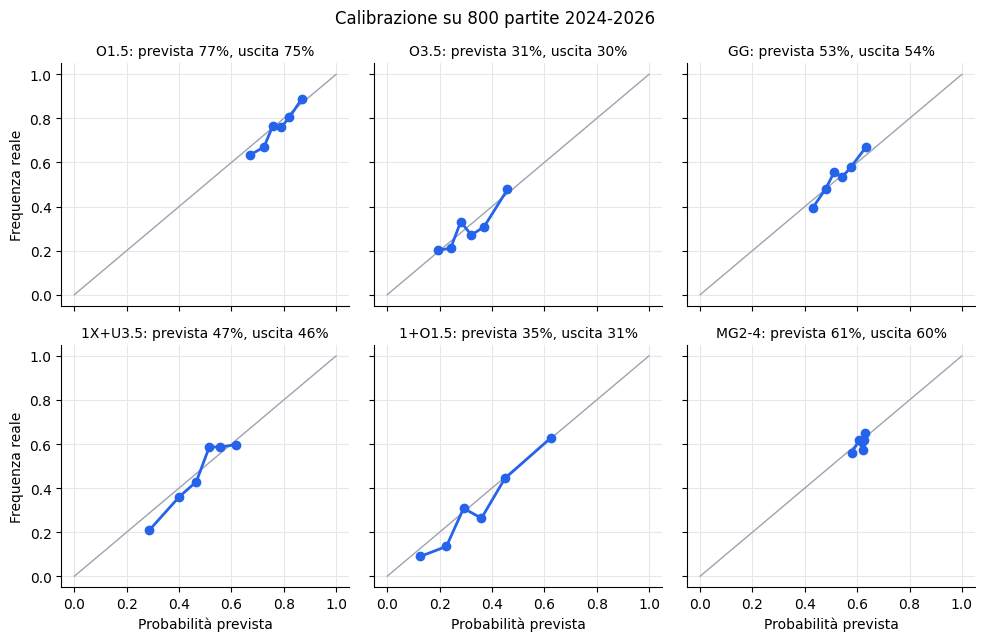

In [6]:
CAMPIONE = 800
DA_VERIFICARE = ["O1.5", "O3.5", "GG", "1X+U3.5", "1+O1.5", "MG2-4"]

files = sorted(Path("data").glob("*_2[45]2[56].csv"))
hist = pd.concat([pd.read_csv(f, encoding="latin1") for f in files])
hist = hist.dropna(subset=["AvgH", "AvgD", "AvgA", "Avg>2.5", "Avg<2.5", "FTHG", "FTAG"])
hist = hist.sample(min(CAMPIONE, len(hist)), random_state=0).reset_index(drop=True)

p1x2 = fair_probs(hist[["AvgH", "AvgD", "AvgA"]].to_numpy(float))
pou = fair_probs(hist[["Avg>2.5", "Avg<2.5"]].to_numpy(float))
res = []
for i in range(len(hist)):
    P = score_grid(*fit_goals(p1x2[i], pou[i, 0]))
    hg, ag = min(int(hist.at[i, "FTHG"]), 10), min(int(hist.at[i, "FTAG"]), 10)
    for sel in DA_VERIFICARE:
        mask = selection_mask(sel)
        res.append((sel, (P * mask).sum(), mask[hg, ag]))
res = pd.DataFrame(res, columns=["Giocata", "Prevista", "Uscita"])

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, (sel, g) in zip(axes.flat, res.groupby("Giocata", sort=False)):
    g = g.assign(fascia=pd.qcut(g["Prevista"], 6, duplicates="drop"))
    c = g.groupby("fascia", observed=True).agg(prev=("Prevista", "mean"), real=("Uscita", "mean"))
    ax.plot([0, 1], [0, 1], color="#9ca3af", linewidth=1)
    ax.plot(c["prev"], c["real"], color=BLU, linewidth=2, marker="o", markersize=6)
    ax.set_title(f"{sel}: prevista {g['Prevista'].mean():.0%}, uscita {g['Uscita'].mean():.0%}", fontsize=10)
    ax.grid(color="#e5e7eb", linewidth=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Probabilità prevista")
for ax in axes[:, 0]:
    ax.set_ylabel("Frequenza reale")
fig.suptitle(f"Calibrazione su {len(hist)} partite 2024-2026", fontsize=12)
plt.tight_layout()
plt.show()